# GIAI ĐOẠN 1: EDA — BỘ DỮ LIỆU ẢNH KHUÔN MẶT UTKFace

**Mục tiêu:**
Trước khi thiết kế kiến trúc mạng **Convolutional Neural Network (CNN)**, chọn **Activation Function**, **Loss Function** hay **Optimizer** cho bài toán **Classification** và **Regression**, chúng ta cần khảo sát thực nghiệm bộ dữ liệu **UTKFace** để trả lời 5 câu hỏi cốt lõi:

1. **Data Integrity**: Bộ dữ liệu tải từ Kaggle (`jangedoo/utkface-new`) có bị trùng lặp thư mục hay có file ảnh nào bị lỗi định dạng tên nhãn (`[age]_[gender]_[race]_[date&time].jpg`) không?
2. **Phân tích biến mục tiêu Regression (`age`)**:
   - Phân phối tuổi là Normal Distribution hay Skewed?
   - Có **Outliers** ở vùng tuổi già hay không? $\rightarrow$ *Căn cứ để chọn giữa `MSE Loss`, `MAE Loss` và `Huber / Smooth L1 Loss`.*
3. **Phân tích biến mục tiêu Classification (`gender` & `race`)**:
   - Tỷ lệ giữa các lớp **Balanced** hay **Imbalanced**? $\rightarrow$ *Căn cứ để quyết định có cần dùng `Class-Weighted Loss` và chọn Metric đánh giá (`Accuracy` vs `Macro F1-Score`).*
4. **Multivariate Analysis**: Phân bố tuổi giữa Nam và Nữ hoặc giữa các nhóm Sắc tộc có đồng đều không?
5. **Image Resolution & Pixel Distribution**: Kích thước ảnh, số kênh màu, trung bình ($\mu$) và độ lệch chuẩn ($\sigma$) của các kênh màu `R, G, B` là bao nhiêu? $\rightarrow$ *Căn cứ để thiết kế bước chuẩn hóa `Normalize` và các lớp `Conv2d` + `BatchNorm2d`.*

## 1. Cài đặt & Import các thư viện

In [1]:
# Cài đặt thư viện tải dữ liệu từ Kaggle
!pip install -q kagglehub

import os
import glob
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch

# Thiết lập hiển thị biểu đồ rõ nét
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_theme(style="whitegrid", palette="deep")

# Cố định seed để kết quả lấy mẫu luôn nhất quán
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print(f"PyTorch version: {torch.__version__}")
print(f"Thiết bị hiện tại: {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")

PyTorch version: 2.11.0+cu130
Thiết bị hiện tại: GPU (Tesla T4)


## 2. Tải bộ dữ liệu UTKFace tự động từ Kaggle (`jangedoo/utkface-new`)

Bộ dữ liệu **UTKFace** của *Sanjaya Subedi* trên Kaggle có mã định danh là `jangedoo/utkface-new`.
- Trong gói tải về của `jangedoo/utkface-new`, tác giả đóng gói tới 3 thư mục con (`UTKFace/`, `utkface_aligned_cropped/UTKFace/`, và `crop_part1/`) chứa các file ảnh trùng tên nhau.
- Chúng ta sẽ kiểm tra cấu trúc thư mục và chỉ lấy duy nhất thư mục chuẩn `UTKFace`.

In [2]:
import kagglehub

print("Đang tải bộ dữ liệu UTKFace từ Kaggle về Colab...")
raw_dataset_path = kagglehub.dataset_download("jangedoo/utkface-new")
print(f"Đường dẫn thư mục tải về: {raw_dataset_path}")

# Khảo sát các thư mục con bên trong gói dữ liệu
print("\n Cấu trúc các thư mục con bên trong:")
for root, dirs, files in os.walk(raw_dataset_path):
    jpg_count = len([f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    rel_path = os.path.relpath(root, raw_dataset_path)
    print(f"  - Thư mục: {rel_path:<40} | Số file ảnh: {jpg_count:,}")

Đang tải bộ dữ liệu UTKFace từ Kaggle về Colab...
Using Colab cache for faster access to the 'utkface-new' dataset.
Đường dẫn thư mục tải về: /kaggle/input/utkface-new

 Cấu trúc các thư mục con bên trong:
  - Thư mục: .                                        | Số file ảnh: 0
  - Thư mục: UTKFace                                  | Số file ảnh: 23,708
  - Thư mục: utkface_aligned_cropped                  | Số file ảnh: 0
  - Thư mục: utkface_aligned_cropped/UTKFace          | Số file ảnh: 23,708
  - Thư mục: utkface_aligned_cropped/crop_part1       | Số file ảnh: 9,780
  - Thư mục: crop_part1                               | Số file ảnh: 9,780


## 3. Data Cleaning

Theo tài liệu chính thức của **UTKFace**, mỗi tên file ảnh được đặt theo quy tắc:
$$\text{[age]}\_\text{[gender]}\_\text{[race]}\_\text{[date\&time]}.\text{jpg}$$

Trong đó:
- **`age`**: Số nguyên từ `1` đến `116`.
- **`gender`**: `0` = **Male**, `1` = **Female**.
- **`race`**:
  - `0` = **White**
  - `1` = **Black**
  - `2` = **Asian**
  - `3` = **Indian**
  - `4` = **Others**

In [3]:
# Chọn thư mục UTKFace chuẩn và loại bỏ các thư mục còn lại
candidate_dir = os.path.join(raw_dataset_path, "UTKFace")
if not os.path.exists(candidate_dir):
    # Nếu cấu trúc thư mục khác, quét toàn bộ nhưng lọc duy nhất theo tên file
    all_image_paths = glob.glob(os.path.join(raw_dataset_path, "**", "*.jpg"), recursive=True)
else:
    all_image_paths = glob.glob(os.path.join(candidate_dir, "*.jpg"))

# Đảm bảo không trùng tên file
unique_files = {}
for p in all_image_paths:
    fname = os.path.basename(p)
    if fname not in unique_files:
        unique_files[fname] = p

print(f"Tổng số file ảnh duy nhất tìm thấy: {len(unique_files):,}")

GENDER_MAP = {0: "Male (Nam)", 1: "Female (Nữ)"}
RACE_MAP = {
    0: "White (Da trắng)",
    1: "Black (Da đen)",
    2: "Asian (Châu Á)",
    3: "Indian (Ấn Độ)",
    4: "Others (Khác)"
}

valid_records = []
corrupted_files = []

for fname, fpath in unique_files.items():
    parts = fname.split("_")
    # Tên file chuẩn phải có ít nhất 4 thành phần: age, gender, race, datetime
    if len(parts) < 4:
        corrupted_files.append((fname, "Thiếu thành phần trong tên file (< 4 trường)"))
        continue
    try:
        age = int(parts[0])
        gender = int(parts[1])
        race = int(parts[2])

        if not (0 <= age <= 120):
            corrupted_files.append((fname, f"Tuổi ngoài miền hợp lệ: {age}"))
            continue
        if gender not in GENDER_MAP:
            corrupted_files.append((fname, f"Nhãn giới tính không hợp lệ: {gender}"))
            continue
        if race not in RACE_MAP:
            corrupted_files.append((fname, f"Nhãn sắc tộc không hợp lệ: {race}"))
            continue

        valid_records.append({
            "filename": fname,
            "filepath": fpath,
            "age": age,
            "gender": gender,
            "gender_name": GENDER_MAP[gender],
            "race": race,
            "race_name": RACE_MAP[race]
        })
    except ValueError as e:
        corrupted_files.append((fname, f"Lỗi ép kiểu số nguyên: {e}"))

df = pd.DataFrame(valid_records)

print(f"Số lượng ảnh hợp lệ: {len(df):,}")
print(f"Số lượng file bị lỗi nhãn đã lọc bỏ: {len(corrupted_files)}")
if corrupted_files:
    print("\nDanh sách các file bị lỗi nhãn trong bộ dữ liệu gốc:")
    for bad_name, reason in corrupted_files[:10]:
        print(f"  - {bad_name:<35} -> Lý do: {reason}")

display(df.head())

Tổng số file ảnh duy nhất tìm thấy: 23,708
Số lượng ảnh hợp lệ: 23,705
Số lượng file bị lỗi nhãn đã lọc bỏ: 3

Danh sách các file bị lỗi nhãn trong bộ dữ liệu gốc:
  - 61_1_20170109142408075.jpg.chip.jpg -> Lý do: Thiếu thành phần trong tên file (< 4 trường)
  - 61_1_20170109150557335.jpg.chip.jpg -> Lý do: Thiếu thành phần trong tên file (< 4 trường)
  - 39_1_20170116174525125.jpg.chip.jpg -> Lý do: Thiếu thành phần trong tên file (< 4 trường)


,filename,filepath,age,gender,gender_name,race,race_name
0,26_0_2_20170104023102422.jpg.chip.jpg,/kaggle/input/utkface-new/UTKFace/26_0_2_20170...,26,0,Male (Nam),2,Asian (Châu Á)
1,22_1_1_20170112233644761.jpg.chip.jpg,/kaggle/input/utkface-new/UTKFace/22_1_1_20170...,22,1,Female (Nữ),1,Black (Da đen)
2,21_1_3_20170105003215901.jpg.chip.jpg,/kaggle/input/utkface-new/UTKFace/21_1_3_20170...,21,1,Female (Nữ),3,Indian (Ấn Độ)
3,28_0_0_20170117180555824.jpg.chip.jpg,/kaggle/input/utkface-new/UTKFace/28_0_0_20170...,28,0,Male (Nam),0,White (Da trắng)
4,17_1_4_20170103222931966.jpg.chip.jpg,/kaggle/input/utkface-new/UTKFace/17_1_4_20170...,17,1,Female (Nữ),4,Others (Khác)


## 4. Phân tích Regression Target Variable: `age`

Trong bài toán **Regression**, việc chọn **Loss Function** và Output Activation Function phụ thuộc vào:
1. **Miền giá trị của biến mục tiêu ($y \in [y_{\min}, y_{\max}]$)**: Có số âm hay không? Thang đo lớn hay nhỏ?
2. **Skewness**: Dữ liệu đối xứng hình chuông hay lệch hẳn về một phía?
3. **Outliers**: Sử dụng quy tắc khoảng tứ phân vị (**IQR Rule**):
   - $\text{IQR} = Q_3 (75\%) - Q_1 (25\%)$
   - Ngưỡng trên phát hiện Outliers: $\text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$

THỐNG KÊ MÔ TẢ BIẾN AGE
  • Số lượng mẫu (N)        : 23,705
  • Giá trị nhỏ nhất (Min)  : 1
  • Giá trị lớn nhất (Max)  : 116
  • Trung bình (Mean)       : 33.30
  • Độ lệch chuẩn (Std)     : 19.89
  • Phân vị 25% (Q1)        : 23.0
  • Trung vị 50% (Median)   : 29.0
  • Phân vị 75% (Q3)        : 45.0
  • Khoảng tứ phân vị (IQR) : 22.0
  • Độ lệch (Skewness)      : 0.622
  • Ngưỡng Outliers         : > 78.0
  • Số lượng ảnh Outliers   : 696 ảnh (2.94% tổng dữ liệu)


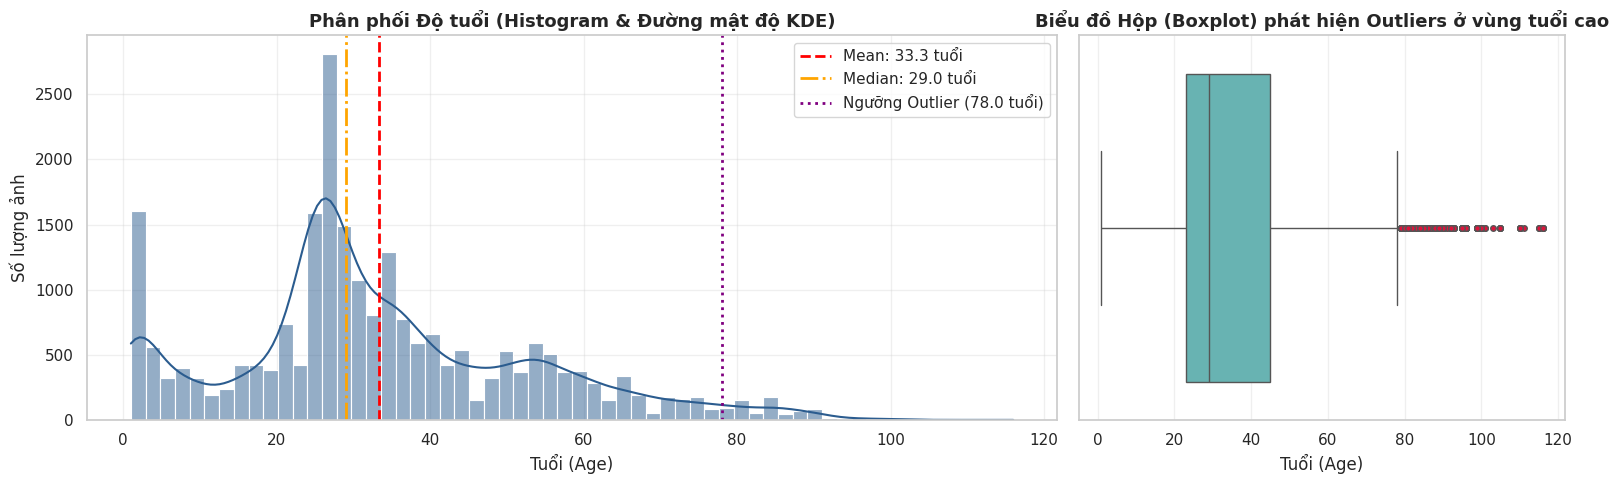

In [4]:
# Tính toán các thống kê mô tả cho biến Age
age_series = df["age"]
q1 = age_series.quantile(0.25)
q2 = age_series.quantile(0.50)
q3 = age_series.quantile(0.75)
iqr = q3 - q1
upper_outlier_bound = q3 + 1.5 * iqr
lower_outlier_bound = max(0, q1 - 1.5 * iqr)

outliers_df = df[df["age"] > upper_outlier_bound]
outlier_ratio = len(outliers_df) / len(df) * 100
skewness = age_series.skew()
kurtosis = age_series.kurt()

print("=" * 65)
print("THỐNG KÊ MÔ TẢ BIẾN AGE")
print("=" * 65)
print(f"  • Số lượng mẫu (N)        : {len(age_series):,}")
print(f"  • Giá trị nhỏ nhất (Min)  : {age_series.min()}")
print(f"  • Giá trị lớn nhất (Max)  : {age_series.max()}")
print(f"  • Trung bình (Mean)       : {age_series.mean():.2f}")
print(f"  • Độ lệch chuẩn (Std)     : {age_series.std():.2f}")
print(f"  • Phân vị 25% (Q1)        : {q1:.1f}")
print(f"  • Trung vị 50% (Median)   : {q2:.1f}")
print(f"  • Phân vị 75% (Q3)        : {q3:.1f}")
print(f"  • Khoảng tứ phân vị (IQR) : {iqr:.1f}")
print(f"  • Độ lệch (Skewness)      : {skewness:.3f}")
print(f"  • Ngưỡng Outliers         : > {upper_outlier_bound:.1f}")
print(f"  • Số lượng ảnh Outliers   : {len(outliers_df):,} ảnh ({outlier_ratio:.2f}% tổng dữ liệu)")
print("=" * 65)

# Vẽ biểu đồ Histogram + KDE và Boxplot
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})

# 1. Histogram + KDE
sns.histplot(df["age"], bins=60, kde=True, color="#2b5c8f", ax=axes[0])
axes[0].axvline(age_series.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {age_series.mean():.1f} tuổi")
axes[0].axvline(q2, color="orange", linestyle="-.", linewidth=2, label=f"Median: {q2:.1f} tuổi")
axes[0].axvline(upper_outlier_bound, color="purple", linestyle=":", linewidth=2, label=f"Ngưỡng Outlier ({upper_outlier_bound:.1f} tuổi)")
axes[0].set_title("Phân phối Độ tuổi (Histogram & Đường mật độ KDE)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Tuổi (Age)")
axes[0].set_ylabel("Số lượng ảnh")
axes[0].legend()

# 2. Boxplot
sns.boxplot(x=df["age"], color="#5bc0be", ax=axes[1], flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "crimson"})
axes[1].set_title("Biểu đồ Hộp (Boxplot) phát hiện Outliers ở vùng tuổi cao", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Tuổi (Age)")

plt.tight_layout()
plt.show()

### Nhận xét từ biểu đồ biến `age` để chọn thuật toán Regression:
1. **Phân phối Right-skewed, Skewness $\approx 0.6 - 0.8$**:
   - Dữ liệu tập trung rất dày ở độ tuổi thanh niên (`20 – 35` tuổi), có một đỉnh phụ ở trẻ sơ sinh (`1 – 2` tuổi).
   - Ở vùng tuổi cao (tương ứng vùng chấm đỏ trên Boxplot), dữ liệu trở thành **Outliers** (chiếm ~3% dữ liệu).
2. **Hệ quả chọn Hàm Loss**:
   - Nếu dùng **`MSELoss`**: Các mẫu ở vùng từ `80 – 116` tuổi sẽ bị bình phương sai số $(y - \hat{y})^2$, tạo ra đạo hàm rất lớn kéo lệch mô hình.
   - Do đó, **`Huber Loss`** hoặc **`MAE`** phù hợp hơn.
3. **Hệ quả chọn Hàm Output Activation**:
   - Toàn bộ giá trị tuổi đều dương ($y \ge 1$). Ở lớp `Linear(in_features, 1)` cuối cùng, ta dùng **Linear**.

## 5. Phân tích Classification Target Variable: `gender` & `race`

Đối với bài toán **Classification**, yếu tố quan trọng nhất từ dữ liệu là **Class Balance**:
- **Imbalance Ratio**:
  $$\text{IR} = \frac{\max_c (N_c)}{\min_c (N_c)}$$
  - Nếu $\text{IR} \approx 1.0 - 1.5$: Dữ liệu **cân bằng** $\rightarrow$ Dùng hàm Loss tiêu chuẩn (`BCEWithLogitsLoss` / `CrossEntropyLoss`) và đánh giá bằng `Accuracy` + `F1-Score`.
  - Nếu $\text{IR} > 3.0$: Dữ liệu **mất cân bằng nặng** $\rightarrow$ Cần cân nhắc gắn trọng số lớp (`class_weights`) vào hàm Loss và bắt buộc đánh giá bằng **Macro F1-Score** + **Confusion Matrix**.

1. PHÂN BỐ NHÃN GENDER
  • Male (Nam)          : 12,391 ảnh (52.27%)
  • Female (Nữ)         : 11,314 ảnh (47.73%)
  => Tỷ lệ mất cân bằng (Imbalance Ratio): 1.10

2. PHÂN BỐ NHÃN RACE
  • White (Da trắng)    : 10,078 ảnh (42.51%)
  • Black (Da đen)      :  4,526 ảnh (19.09%)
  • Indian (Ấn Độ)      :  3,975 ảnh (16.77%)
  • Asian (Châu Á)      :  3,434 ảnh (14.49%)
  • Others (Khác)       :  1,692 ảnh (7.14%)
  => Tỷ lệ mất cân bằng (Imbalance Ratio): 5.96

Trọng số lớp (Class Weights) gợi ý nếu train phân loại Race:
  • Class 0 (White (Da trắng)  ): N = 10,078 -> weight = 0.470
  • Class 1 (Black (Da đen)    ): N =  4,526 -> weight = 1.048
  • Class 2 (Asian (Châu Á)    ): N =  3,434 -> weight = 1.381
  • Class 3 (Indian (Ấn Độ)    ): N =  3,975 -> weight = 1.193
  • Class 4 (Others (Khác)     ): N =  1,692 -> weight = 2.802


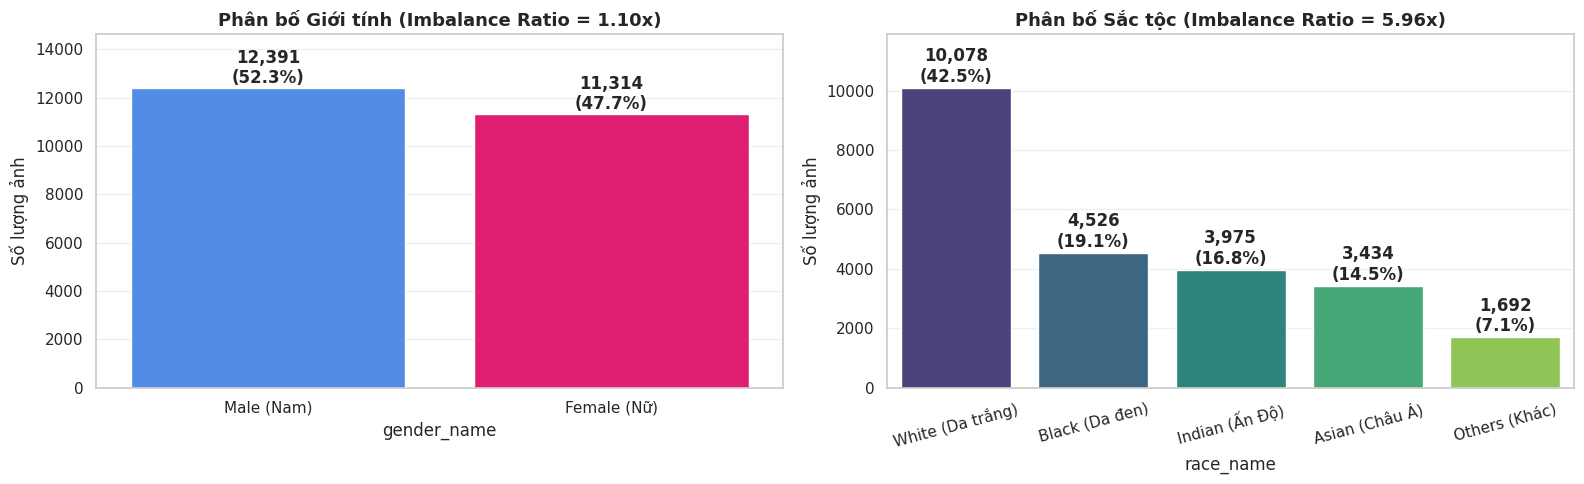

In [5]:
# Thống kê số lượng và tỷ lệ % cho Gender và Race
gender_counts = df["gender_name"].value_counts()
gender_pct = df["gender_name"].value_counts(normalize=True) * 100
gender_ir = gender_counts.max() / gender_counts.min()

race_counts = df["race_name"].value_counts()
race_pct = df["race_name"].value_counts(normalize=True) * 100
race_ir = race_counts.max() / race_counts.min()

print("=" * 65)
print("1. PHÂN BỐ NHÃN GENDER")
print("=" * 65)
for name in gender_counts.index:
    print(f"  • {name:<20}: {gender_counts[name]:>6,} ảnh ({gender_pct[name]:.2f}%)")
print(f"  => Tỷ lệ mất cân bằng (Imbalance Ratio): {gender_ir:.2f}")

print("\n" + "=" * 65)
print("2. PHÂN BỐ NHÃN RACE")
print("=" * 65)
for name in race_counts.index:
    print(f"  • {name:<20}: {race_counts[name]:>6,} ảnh ({race_pct[name]:.2f}%)")
print(f"  => Tỷ lệ mất cân bằng (Imbalance Ratio): {race_ir:.2f}")

# Tính trọng số cân bằng lớp (Balanced Class Weights): w_c = N_total / (C * N_c)
num_classes_race = len(RACE_MAP)
total_samples = len(df)
print("\nTrọng số lớp (Class Weights) gợi ý nếu train phân loại Race:")
for r_id, r_name in RACE_MAP.items():
    n_c = (df["race"] == r_id).sum()
    weight_c = total_samples / (num_classes_race * n_c)
    print(f"  • Class {r_id} ({r_name:<18}): N = {n_c:>6,} -> weight = {weight_c:.3f}")

# Vẽ biểu đồ trực quan
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ Gender
sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values,
    hue=gender_counts.index,
    palette=["#3a86ff", "#ff006e"],
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    f"Phân bố Giới tính (Imbalance Ratio = {gender_ir:.2f}x)",
    fontsize=13,
    fontweight="bold",
)
axes[0].set_ylabel("Số lượng ảnh")
for i, v in enumerate(gender_counts.values):
  axes[0].text(
      i,
      v + 200,
      f"{v:,}\n({gender_pct.iloc[i]:.1f}%)",
      ha="center",
      fontweight="bold",
  )
axes[0].set_ylim(0, gender_counts.max() * 1.18)

# Biểu đồ Race
sns.barplot(
    x=race_counts.index,
    y=race_counts.values,
    hue=race_counts.index,
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    f"Phân bố Sắc tộc (Imbalance Ratio = {race_ir:.2f}x)",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_ylabel("Số lượng ảnh")
axes[1].tick_params(axis="x", rotation=15)
for i, v in enumerate(race_counts.values):
  axes[1].text(
      i,
      v + 200,
      f"{v:,}\n({race_pct.iloc[i]:.1f}%)",
      ha="center",
      fontweight="bold",
  )
axes[1].set_ylim(0, race_counts.max() * 1.18)

plt.tight_layout()
plt.show()

## 6. Phân tích Multivariate Analysis: `Age` theo `Gender` & `Race`

Thống kê Độ tuổi trung bình theo từng nhóm Giới tính:


,count,mean,median,std,min,max
gender_name,,,,,,
Female (Nữ),11314,30.68,26.0,19.75,1,116
Male (Nam),12391,35.70,34.0,19.71,1,110



Thống kê Độ tuổi trung bình theo từng nhóm Sắc tộc:


,count,mean,median,std,min,max
race_name,,,,,,
Asian (Châu Á),3434,25.87,26.0,20.41,1,116
Black (Da đen),4526,33.86,30.0,14.83,1,115
Indian (Ấn Độ),3975,31.53,28.0,16.98,1,116
Others (Khác),1692,23.17,25.0,14.49,1,85
White (Da trắng),10078,37.98,35.0,21.94,1,116


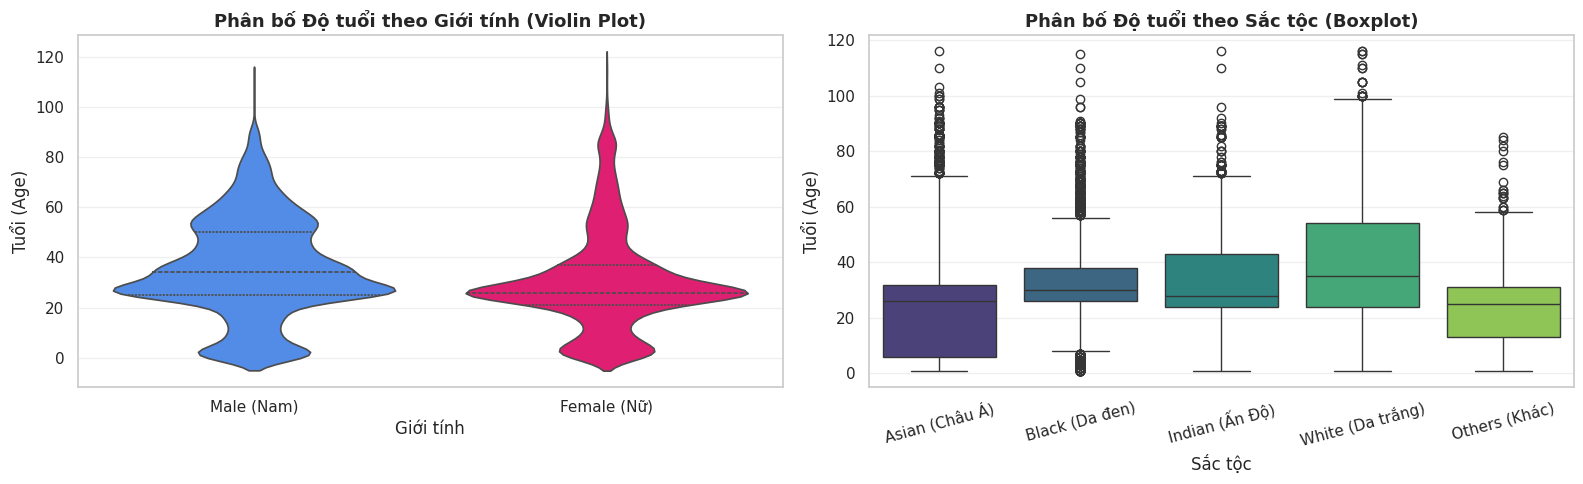

In [6]:
print("Thống kê Độ tuổi trung bình theo từng nhóm Giới tính:")
display(df.groupby("gender_name")["age"].agg(["count", "mean", "median", "std", "min", "max"]).round(2))

print("\nThống kê Độ tuổi trung bình theo từng nhóm Sắc tộc:")
display(df.groupby("race_name")["age"].agg(["count", "mean", "median", "std", "min", "max"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Violin plot: Age by Gender
sns.violinplot(
    data=df,
    x="gender_name",
    y="age",
    hue="gender_name",
    palette=["#3a86ff", "#ff006e"],
    inner="quartile",
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    "Phân bố Độ tuổi theo Giới tính (Violin Plot)",
    fontsize=13,
    fontweight="bold",
)
axes[0].set_xlabel("Giới tính")
axes[0].set_ylabel("Tuổi (Age)")

# Boxplot: Age by Race
sns.boxplot(
    data=df,
    x="race_name",
    y="age",
    hue="race_name",
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    "Phân bố Độ tuổi theo Sắc tộc (Boxplot)", fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Sắc tộc")
axes[1].set_ylabel("Tuổi (Age)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 7. Đặc trưng Images

Mạng CNN làm việc trực tiếp trên ma trận điểm ảnh (Tensor có kích thước $C \times H \times W$). Do đó ta cần kiểm tra:
1. Tất cả các ảnh có cùng kích thước $(H, W)$ và cùng có $3$ kênh màu `RGB` không?
2. Giá trị trung bình ($\mu$) và độ lệch chuẩn ($\sigma$) của các pixel trên 3 kênh `R, G, B` là bao nhiêu?
3. Quan sát trực quan 15 bức ảnh mẫu từ các độ tuổi/giới tính khác nhau để đánh giá độ khó thực tế của bài toán.

THỐNG KÊ ĐẶC TRƯNG NGẪU NHIÊN 1000 ẢNH
  • Kích thước ảnh (Width x Height) phổ biến nhất : [((200, 200), 1000)]
  • Hệ màu (Color Mode)                           : {'RGB': 1000}
  • Pixel Mean (R, G, B) trong đoạn [0, 1]        : [0.5926, 0.4526, 0.3864]
  • Pixel Std  (R, G, B) trong đoạn [0, 1]        : [0.2573, 0.2288, 0.2246]


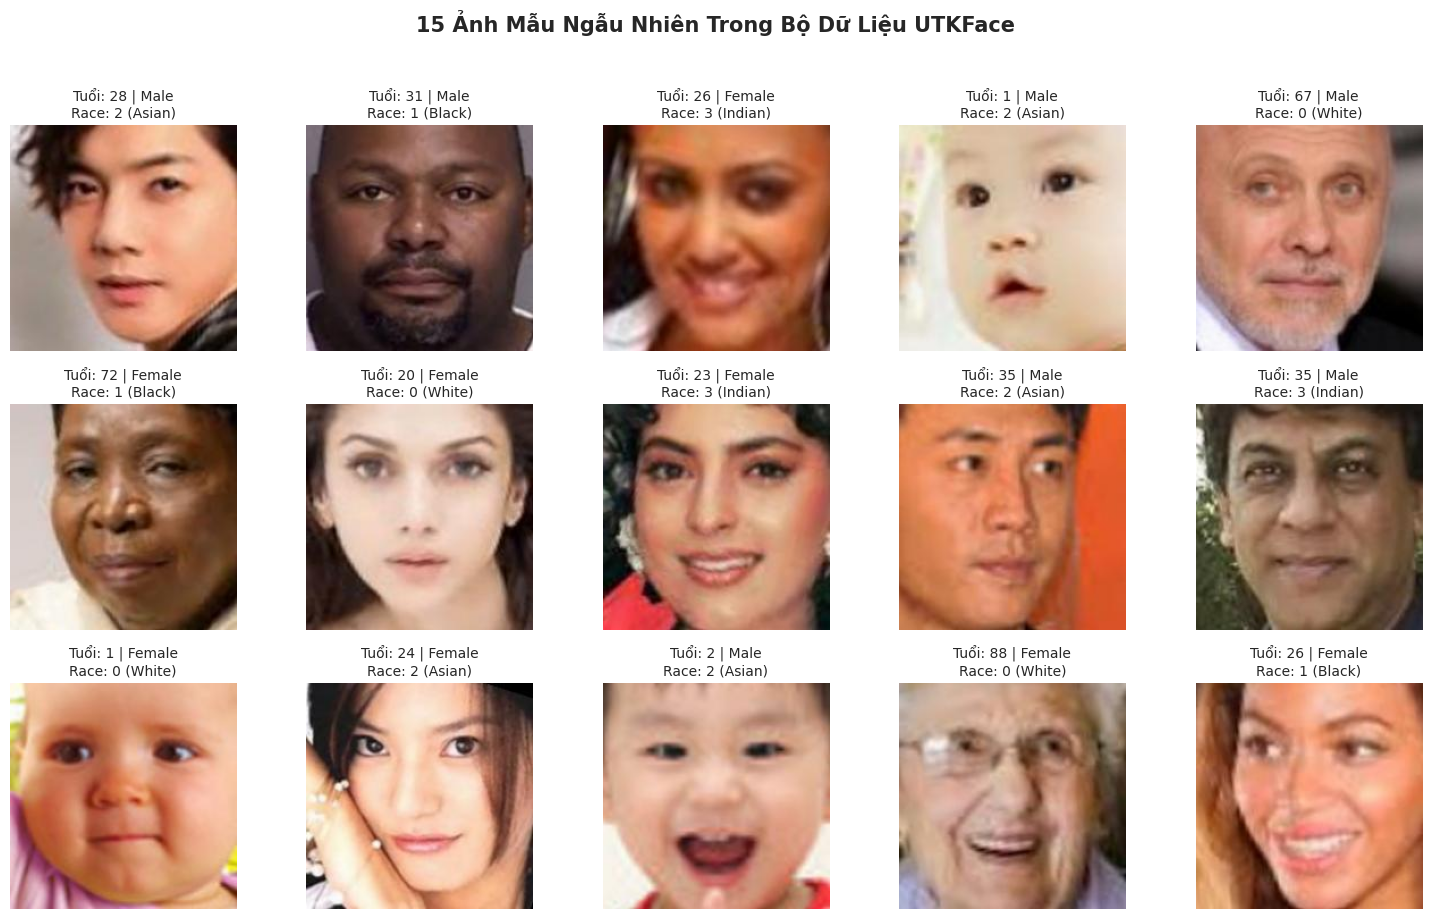

In [7]:
# Lấy mẫu ngẫu nhiên 1,000 ảnh để kiểm tra kích thước, kênh màu và tính Mean/Std của Pixel
sample_df = df.sample(n=min(1000, len(df)), random_state=SEED)

sizes = Counter()
modes = Counter()
channel_sum = np.zeros(3, dtype=np.float64)
channel_sq_sum = np.zeros(3, dtype=np.float64)
total_pixels = 0

for fpath in sample_df["filepath"]:
    with Image.open(fpath) as img:
        sizes[img.size] += 1
        modes[img.mode] += 1
        rgb_img = img.convert("RGB")
        arr = np.asarray(rgb_img, dtype=np.float64) / 255.0  # Quy về [0, 1]
        h, w, _ = arr.shape
        total_pixels += h * w
        channel_sum += arr.sum(axis=(0, 1))
        channel_sq_sum += (arr ** 2).sum(axis=(0, 1))

pixel_mean = channel_sum / total_pixels
pixel_std = np.sqrt(channel_sq_sum / total_pixels - pixel_mean ** 2)

print("=" * 65)
print("THỐNG KÊ ĐẶC TRƯNG NGẪU NHIÊN 1000 ẢNH")
print("=" * 65)
print(f"  • Kích thước ảnh (Width x Height) phổ biến nhất : {sizes.most_common(5)}")
print(f"  • Hệ màu (Color Mode)                           : {dict(modes)}")
print(f"  • Pixel Mean (R, G, B) trong đoạn [0, 1]        : [{pixel_mean[0]:.4f}, {pixel_mean[1]:.4f}, {pixel_mean[2]:.4f}]")
print(f"  • Pixel Std  (R, G, B) trong đoạn [0, 1]        : [{pixel_std[0]:.4f}, {pixel_std[1]:.4f}, {pixel_std[2]:.4f}]")
print("=" * 65)

# Hiển thị lưới 15 ảnh mẫu ngẫu nhiên
vis_samples = df.sample(n=15, random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for idx, ax in enumerate(axes.flat):
    row = vis_samples.iloc[idx]
    with Image.open(row["filepath"]) as img:
        ax.imshow(img)
    ax.set_title(f"Tuổi: {row['age']} | {row['gender_name'].split()[0]}\nRace: {row['race']} ({row['race_name'].split()[0]})", fontsize=10)
    ax.axis("off")

plt.suptitle("15 Ảnh Mẫu Ngẫu Nhiên Trong Bộ Dữ Liệu UTKFace", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()